In [1]:
import numpy as np
import pandas as pd
import cv2
from matplotlib import pyplot as plt
from numpy.linalg import inv
import os

# Color Reproduce Model

In [2]:
class ColorReproducer:
    
    def __init__(self): 
        self.light_spec = None
        self.cmf = None
        self.ma = None
        self.d65 = np.array([0.95047, 1.00000000, 1.08883])
        self.is_ignore_ca = False
        
        self.light_spec_x3 = None
        self.cal_fact = None
        self.k = None
        self.white_light_k = None
        
    def prepare(self):
        self.light_spec_x3 = np.array([self.light_spec,self.light_spec,self.light_spec]).T 
        self.cal_fact = self.cmf * self.light_spec_x3
        self.k = 100.0 / sum(self.cal_fact[:,1])
        self.white_light_k = np.dot(self.cmf.T, self.light_spec) * (self.k / 100.0)
        self.cal_fact = self.cal_fact * self.k
 
        return

    def load(self, setup_path):
        self.light_spec = np.loadtxt(os.path.join(setup_path, 'CR_light.txt'))
        self.cmf = np.loadtxt(os.path.join(setup_path, 'CR_cmf.txt'))
        self.ma = np.loadtxt(os.path.join(setup_path, 'CR_ma.txt'))
        
        self.prepare()
        return
        
    def reproduce(self, img_spec, gain = 1.0, is_normalize = False, filter_band = None):
        
        h,w,c = img_spec.shape
        
        img_spec = img_spec.reshape((-1,c));
        
        fact = None
        
        if self.is_ignore_ca:
            fact = self.cal_fact
        else:
            fact = inv(self.ma).dot(np.diag(self.ma.dot(self.d65) / self.ma.dot(self.white_light_k))).dot(self.ma)
            fact = fact.dot(self.cal_fact.T).T 
            
        op_ref_spec = None
        
        if filter_band is not None:

            filter_band_set = filter_band - 380

            mask = np.zeros((w*h, 401))
            
            mask[:,filter_band_set] = 1

            op_ref_spec = img_spec * mask * gain

        else:

            op_ref_spec = img_spec * gain
        
        
        if is_normalize: 
            
            img_rep_xyz = op_ref_spec.dot(fact)

            min_v = img_rep_xyz.min()
            max_v = img_rep_xyz.max()

            img_rep_xyz = (img_rep_xyz - min_v) / (max_v - min_v) * 255.0
            
        else:
            
            img_rep_xyz = op_ref_spec.dot(fact) / 100.0 * 255.0
         
        img_rep_xyz = img_rep_xyz.reshape(h, w, 3).astype('uint8')
                
        img_rep_rgb = cv2.cvtColor(img_rep_xyz, cv2.COLOR_XYZ2RGB)
        
        return img_rep_rgb

# Function to display band selected

In [3]:
def display_band_selected(filter_band):
    
    filter_band_set = filter_band - 380
    
    x = np.arange(380, 781, 1)

    select_mask = np.zeros((401))

    select_c = 'g'
    unselect_c = 'gray'
    
    select_mask = select_mask + 0.5
    select_mask[filter_band_set] = 1
 
    plt.figure(figsize=(15, 1))
    plt.title('Select band info')
    plt.xlim(380, 781)
    plt.ylim(0, 1.0)
    plt.xticks(np.arange(380, 781, 10))
    plt.yticks([])
    plt.grid(True)
    barlist = plt.bar(x, select_mask, width=1, color=unselect_c)
    
    for i in filter_band_set:
        barlist[i].set_color(select_c)
        
    plt.show()

# Load ColorReproducer

In [4]:
reproducer = ColorReproducer()
reproducer.load('cr_weights')

# Test Color Reproduce

In [8]:
# load image spectrum
img_spec = np.load('')
print('img_spec shape', img_spec.shape)

# color reproduce
gain = 1.0
is_normalize = True
filter_band = np.arange(400, 600, 1)

img_rep_rgb = reproducer.reproduce(img_spec, gain, is_normalize, filter_band)

print('img_rep_rgb shape', img_rep_rgb.shape)

display_band_selected(filter_band)

img_spec shape (6, 6)


ValueError: not enough values to unpack (expected 3, got 2)

In [6]:
plt.figure(figsize=(8, 8))
plt.imshow(img_rep_rgb)
plt.title('Reproduction image from spectrum')
plt.show()

NameError: name 'img_rep_rgb' is not defined

<Figure size 576x576 with 0 Axes>

# Original Image

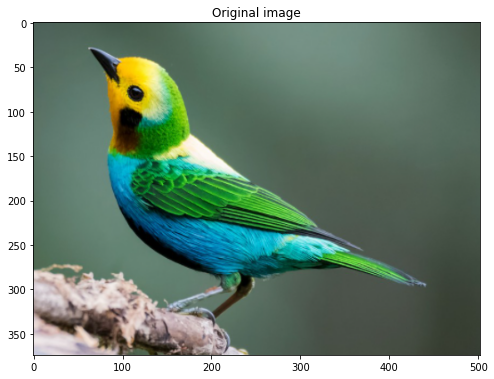

In [16]:
img_org = cv2.imread('C:\\Users\\Arvind\\Downloads\\skin_cancer_wli-20240815T020033Z-001\\skin_cancer_wli\\SCC\\ISIC_0012762.jpg')
img_org = cv2.cvtColor(img_org, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 8))
plt.imshow(img_org)
plt.title('Original image')
plt.show()

# Compare

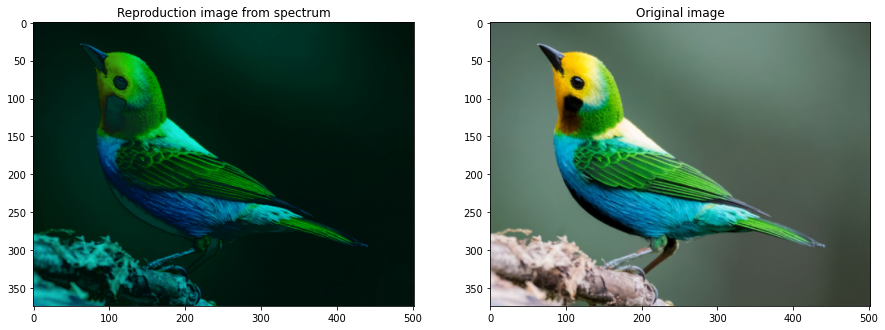

In [17]:
plt.figure(figsize=(15, 6))

plt.subplot(1,2,1)
plt.imshow(img_rep_rgb)
plt.title('Reproduction image from spectrum')

plt.subplot(1,2,2)
plt.imshow(img_org)
plt.title('Original image')
plt.show()